# Real Solar Multi-object Wavefront Blind Deconvolution

## 1. Problem

Recover two sharp solar intensity images and atmospheric pupil phases from a real burst of twelve simultaneous broadband/narrowband exposure pairs. The full detector field is 512 by 512 pixels. A single image-wide convolution kernel cannot describe the spatially varying residual seeing: 121 overlapping isoplanatic regions share twelve time-dependent phases between passbands but have different phases across the field.

This notebook **actively reconstructs all observations** with local explicit mathematical modules. The comparison labeled "reproduced upstream" comes from a separately executed original implementation on the same observations. The traditional MOMFBD comparison is an archived independent processing product. Neither is a physical sharp-image truth. No cached-preview path replaces active reconstruction.

The submitted quantities are two 476-square intensity mosaics, 2 by 121 local 88-square intensity objects, and 121 by 12 by 54 phase coefficients in radians. First-exposure tip/tilt is fixed to zero; the final coefficient slot is an explicitly declared null basis function. The task therefore does not claim 54 independently observable atmospheric modes.


In [1]:
%matplotlib inline
from pathlib import Path
import sys, json, subprocess, platform
import numpy as np
import scipy
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.preprocessing import load_data, normalize_frames, extract_patches, mosaic
from src.physics_model import build_optics
from src.solvers import reconstruct
from src.visualization import (plot_data, plot_comparison, plot_wavefront,
                               plot_diagnostics, plot_differences, contrast)
torch.set_num_threads(1)
print('Python', platform.python_version(), 'NumPy', np.__version__, 'SciPy', scipy.__version__)
print('Torch', torch.__version__, 'device', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

Python 3.11.11 NumPy 2.4.6 SciPy 1.17.1
Torch 2.9.1+cu128 device NVIDIA GeForce RTX 4080 SUPER


## 2. Data

The observations are **real SST/CRISP solar measurements**, not simulated blurred images. The instrument observed quiet Sun on 2019-08-01 at 08:15:47, near Ca II 8542 Angstrom at +65 milli-Angstrom from line center. The public archive is https://cloud.iac.es/index.php/s/EqMGsqBeyfq6Bnr ; the original file is `obs/qs_20190801_081547_8542_npix512_original.h5`, SHA256 `b9294e228b7000be77cf4536befee318023be7e7f8fba02b51531fabc5941c1e`.

Its complete `im` array was stored losslessly in NPZ: one burst, broadband then narrowband, all twelve simultaneous exposure pairs, and all 512-square pixels. There is no new noise, blur injection, resampling, numerical downcast or frame selection. The observational script records an extraction origin of (200,200) in its larger input detector field; this task retains the entire supplied extracted observation.

The theoretical KL mixing coefficients come from the exact source revision `b27a963cdb995cdd73695a17cddd589cb6367421` of https://github.com/aasensio/torchmfbd . They depend on an atmospheric basis convention, not the target solar image or fitted unknown phase. The parent archive and source hashes are indexed in `test/validation.md`.

| Key | Shape | Dtype | Description |
|---|---|---|---|
| observations | (1,2,12,512,512) | float32 | Burst, passband, exposure, detector row, detector column; original calibrated digital intensity units |
| kl_mixing | (1,436,3) | float32 | Batch, theoretical mixing record, field; one-based KL index, one-based Noll Zernike index, dimensionless coefficient |

Acquisition geometry is a clear 100-cm aperture, 0.059 arcsec pixels, effective 8542-Angstrom diffraction/phase wavelength for both channels, 17-ms exposure duration and 1.2-s burst duration. The broadband prefilter FWHM is 0.83 nm. The local model uses 88-square regions, stride 40, no padding and circular local convolution. Preserve both the integer-centered aperture grid and the distinct inclusive symmetric KL-coordinate grid. Absolute radiometric calibration and independently measured noise variances are unavailable.

The figure compares the first measured frame, the exposure with maximum broadband RMS contrast, and the burst average. Best-exposure selection is **only a comparison baseline**: the inverse solver uses every frame.


observations (1, 2, 12, 512, 512) float32
kl_mixing (1, 436, 3) float32
Retained measured samples: 6291456


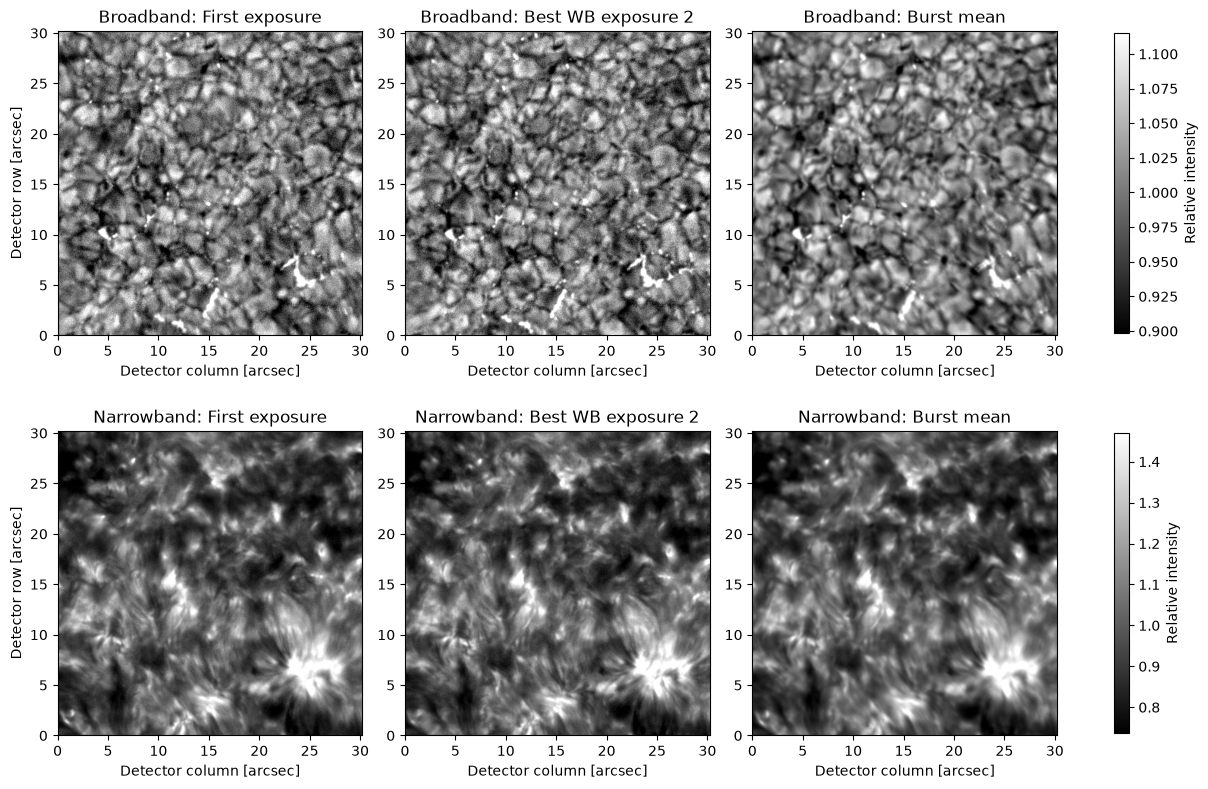

In [2]:
observations, mixing = load_data(ROOT/'data/raw_data.npz')
with np.load(ROOT/'data/raw_data.npz', allow_pickle=False) as raw:
    for key in raw.files:
        print(key, raw[key].shape, raw[key].dtype)
print('Retained measured samples:', observations.size)
plot_data(observations)
plt.show()

## 3. Physics

For channel $k$, region $p$, exposure $j$, the local image is $d_{kpj}=o_{kp}*h_{pj}+n_{kpj}$. Here $d$ is the measurement divided by its complete frame mean, $o$ is relative solar intensity, $h$ is a unit-flux atmospheric/telescope PSF, $n$ is noise, and $*$ denotes periodic discrete convolution on an 88-square region. The same atmospheric phase applies to both simultaneous channels.

Let $A$ be the known clear-aperture mask, $B_m$ a dimensionless KL phase basis and $a_{pjm}$ its unknown coefficient in radians. Then


$$
\phi_{pj}(v)=\sum_m a_{pjm}B_m(v),\quad P_{pj}(v)=A(v)e^{i\phi_{pj}(v)},\quad h_{pj}=\frac{|\mathcal F_oP_{pj}|^2}{\sum_r|\mathcal F_oP_{pj}(r)|^2}.
$$


$v$ and $r$ denote pupil and image grid indices; $\mathcal F_o$ is the negative-sign, orthonormal two-dimensional forward FFT. The pupil overfill is $g=206265\lambda/(D\Delta)$, with wavelength $\lambda$ and aperture diameter $D$ both in cm and sampling $\Delta$ in arcsec/pixel. Integer pupil coordinates run from -44 through 43. KL polynomials instead use 88 inclusive samples from -1 to 1, scaled radially by $g$; this distinct grid convention is preserved from the independently run implementation.

Each KL function is a supplied linear combination of Noll-normalized Zernike polynomials. For radial order $n$, absolute azimuthal order $m$, and $q=(n-m)/2$, the radial polynomial is $R_n^m(\rho)=(-1)^q\rho^m P_q^{(m,0)}(1-2\rho^2)$, where $P_q^{(m,0)}$ is an ordinary Jacobi polynomial. Cosine or sine angular factors and the Noll square-root normalization form the complete Zernike function. The local code evaluates this formula and the mixing explicitly.

The 54-slot convention contains KL indices 2 through 54 followed by a zero slot, inherited from an upstream allocation/loop discrepancy. The null slot is declared rather than counted as a measurable physical phase mode. First-exposure tip/tilt is subtracted in every region to remove an image-translation gauge. No piston is included.

With $N=88$, $S=\mathcal F_o(h)$ has DC value $1/N$. Observed $I=\mathcal F_o(d)$ and the ordinary object spectrum $O$ satisfy $I=OS$. Final object reconstruction uses the ordinary inverse FFT. These mixed transform conventions cancel correctly; treating $S(0)$ as one without changing other transforms would produce a factor-88 scale error.


In [3]:
optics = build_optics(mixing)
print('Aperture support pixels:', int(optics['pupil'].sum()))
print('Nonzero basis functions:', int(torch.count_nonzero(torch.linalg.vector_norm(optics['basis'].reshape(54,-1), dim=1))))
print('Local OTF DC convention:', 1/88)
print('Effective diffraction angle [arcsec]:', np.float32(8542)*1e-8/100*206265)

Aperture support pixels: 673
Nonzero basis functions: 53
Local OTF DC convention: 0.011363636363636364
Effective diffraction angle [arcsec]: 0.17619155


## 4. Method

Normalize each full frame, extract all 121 overlapping regions and taper each local frame around its spatial mean with a six-pixel Hann border. For numerical parity, taper on the selected reconstruction device, copy the prepared frames to a contiguous CPU buffer for their FFT, then transfer spectra back to the reconstruction device. Estimate each untapered patch-frame noise $\sigma_{kpj}$ using the median square-root singular value of its spatial covariance. Specifically, $\sigma=\operatorname{median}\sqrt{s}/(\sqrt L\ell/\omega)$, where $s$ are covariance singular values, $L=88$, $\beta=88/88$, $\ell=\sqrt{2(\beta+1)+8\beta/(\beta+1+\sqrt{\beta^2+14\beta+1})}$ and $\omega=0.56\beta^3-0.95\beta^2+1.82\beta+1.43$.

The selected joint-MAP wavefront loss analytically eliminates the latent object. With constant object spectral power $U=100$, scalar channel noise variance $v_k=\operatorname{mean}_{p,j}\sigma_{kpj}^2$, and orthonormal data/OTF arrays $I,S$, define


$$
Q=v_k+U\sum_j|S_j|^2,\qquad D=\sum_j|I_j|^2,\qquad C=\sum_j I_j\overline S_j.
$$


The loss is the sum across channels of the mean of $M[D-U|C|^2/Q]/(2v_k)$ over regions and frequency indices `[1:,1:]`. $M$ equals one below 0.85 of the diffraction cutoff, zero above 0.90, and a cosine transition between. The slicing removes both full zero-frequency axes, a disclosed original-code convention rather than just DC removal. The mask cosine is evaluated on the reconstruction device, preserving upstream GPU rounding. No nonzero wavelet or additional object regularizer is active.

Initialize all phase coefficients to zero and run exactly 250 Adam updates with learning rate 0.08, beta values (0.9,0.999), epsilon $10^{-8}$ and no weight decay. Start with two active tip modes. Continue through radial-degree endpoints 2,5,9,14,20,27,35,44,54 between 10% and 60% of the iteration budget. The schedule is applied after each update. The original constructs but never steps a cosine scheduler, so the local implementation correctly keeps a constant learning rate.

Finally, use per-frame weights $\gamma_{kpj}=\overline{\sigma^2}_{kp}/(\sigma_{kpj}^2+10^{-10})$, normal spectrum $T=\sum_j\gamma_j\overline S_jS_j$, and cross spectrum $G=\sum_j\gamma_j\overline S_jI_j$ to obtain $O=G/(T+10^{-10})$. This final weighting differs from the scalar-noise reduced objective and is preserved explicitly.

For spectral support, median-filter the shifted ratio $\operatorname{Re}[T/(\overline GG)]$ with a periodic 3-square window, multiply by the global channel mean noise variance, and form $f=1-\overline{\sigma^2}H$. This global variance differs from the region-specific mean used in frame weights. Set $f<0.2$ to zero and clip above one. Retain the eight-connected central-frequency component admitted by the original flood tolerance 0.9 on $1-f$, shift back, and multiply by $M$. Apply this binary support to $O$ before the ordinary inverse FFT. No positivity ADMM or pretrained inverse is used.

Discard six pixels at each reconstructed local edge and combine 76-square interiors with 30-pixel cosine weighting at stride 40. Divide by accumulated weights plus $10^{-10}$. The resulting 476-square mosaic covers detector `[6:482,6:482]` and has zero outermost edges. The complete scene and all exposure pairs are actively processed in the following cell.


In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
def progress(index, loss, active):
    if index % 50 == 0 or index == 249:
        print(f'Update {index+1}/250: active={active}, loss={loss:.9g}', flush=True)
fresh = reconstruct(observations, mixing, device=device, progress=progress)
print(f'Fresh complete reconstruction runtime: {fresh["runtime_seconds"]:.3f} s')
(ROOT/'output').mkdir(exist_ok=True)
prediction = ROOT/'output/reconstruction.npz'
np.savez_compressed(prediction, **{key:fresh[key] for key in ('reconstruction','objects','wavefront_coefficients')})
for key in ('reconstruction','objects','wavefront_coefficients'):
    print(key, fresh[key].shape, fresh[key].dtype)

Update 1/250: active=2, loss=20.0986767


Update 51/250: active=5, loss=9.72598076


Update 101/250: active=20, loss=9.18962097


Update 151/250: active=44, loss=9.4803524


Update 201/250: active=54, loss=8.83034992


Update 250/250: active=54, loss=8.76029491


Fresh complete reconstruction runtime: 15.107 s


reconstruction (1, 2, 476, 476) float32
objects (1, 2, 121, 88, 88) float32
wavefront_coefficients (1, 121, 12, 54) float32


## 5. Results

The table and figures distinguish **fresh local measurements** from the **independently reproduced upstream run** on the bound data and the **archived traditional MOMFBD processing**. The traditional files were separately retrieved from the observation archive. The supplied script references a nonexistent `camXXV` file; the actual narrowband product is `camXIX`, independently identified by image-content correlations. After the original horizontal reversal, a raw detector origin at comparison pixel (183,187) was independently measured from the observations; the displayed mosaic comparison crop is `[189:665,193:669]`, divided by its own mean in each passband. This display-only registration never enters Judge alignment or the reference solver.

Evaluate all three declared output arrays. Intensity NCC is uncentered cosine similarity. Intensity NRMSE is RMS error divided by the comparison array's dynamic range. Wavefront PSF relative error is the L2 norm of the unit-flux PSF difference divided by reference PSF norm. Observation relative error is the L2 residual of every local measured frame under the inferred object and wavefront. These metrics measure reference agreement and model consistency, not accuracy against an unknown true Sun.

Best measured exposure, original reconstruction, fresh reconstruction and traditional processing are shown for both passbands at identical spatial scale. RMS contrast excludes only the known one-pixel zero mosaic border for every comparison and is a descriptive statistic, not a hidden evaluation crop. The power-spectrum plots retain both channels and must be interpreted with caution at high frequencies because independent patch mosaics can introduce structure.

The PSF comparison evaluates the inferred phases through their unit-flux optical response, rather than requiring individually unique phase coefficients. This complements intensity and local-observation metrics while respecting tip/tilt and null-basis conventions.


In [5]:
with np.load(ROOT/'evaluation/baseline_reference.npz',allow_pickle=False) as reference:
    upstream = reference['reconstruction'][0]
with np.load(ROOT/'notebooks/reference_outputs/upstream_measurements.npz',allow_pickle=False) as reference:
    upstream_loss = reference['loss_history'][0]
    upstream_runtime = float(reference['runtime_seconds'][0])
with np.load(ROOT/'notebooks/reference_outputs/traditional_comparison.npz',allow_pickle=False) as reference:
    traditional = reference['reconstruction'][0]
normalized = normalize_frames(observations)
best_index = int(np.argmax(np.std(normalized[0].numpy(),axis=(-1,-2))))
patches = extract_patches(normalized)
best = mosaic(torch.stack([patches[k][:,best_index] for k in range(2)])).numpy()
print('Best measured broadband exposure index:',best_index)
print('Original oracle runtime:',upstream_runtime,'s; active local runtime:',fresh['runtime_seconds'],'s')
completed = subprocess.run([sys.executable,str(ROOT/'evaluation/judge.py'),'--prediction',str(prediction),
                            '--report',str(ROOT/'output/judge_report.json')],capture_output=True,text=True)
print(completed.stdout)
if completed.returncode != 0:
    raise RuntimeError('Independent Judge failed: '+completed.stderr)
report = json.loads((ROOT/'output/judge_report.json').read_text(encoding='utf-8'))
print('Metric | Fresh measurement | Boundary')
for key,value in report['metrics'].items():
    entry=report['thresholds'][key]
    print(key,format(value,'.12g'),entry['comparison'],format(entry['boundary'],'.12g'))

Best measured broadband exposure index: 2
Original oracle runtime: 16.92630386352539 s; active local runtime: 15.106986499973573 s


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc_min": 0.9999999999999917,
    "reconstruction_nrmse_max": 2.990655424569937e-08,
    "objects_ncc_min": 0.9999999999999848,
    "objects_nrmse_max": 4.4803136099958475e-08,
    "wavefront_psf_relative_error": 1.6113642130485458e-07,
    "observation_relative_error": 0.01818781167876641,
    "mosaic_relative_error": 0.0,
    "translation_gauge_max": 0.0,
    "null_slot_max": 0.0
  },
  "thresholds": {
    "reconstruction_ncc_min": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "reconstruction_nrmse_max": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "objects_ncc_min": {
      "comparison": ">=",
      "boundary": 0.99999
    },
    "objects_nrmse_max": {
      "comparison": "<=",
      "boundary": 0.002
    },
    "wavefront_psf_relative_error": {
      "comparison": "<=",
      "boundary": 0.01
    },
    "observation_relative_error": {
      "comparison": "<=",
      "boun

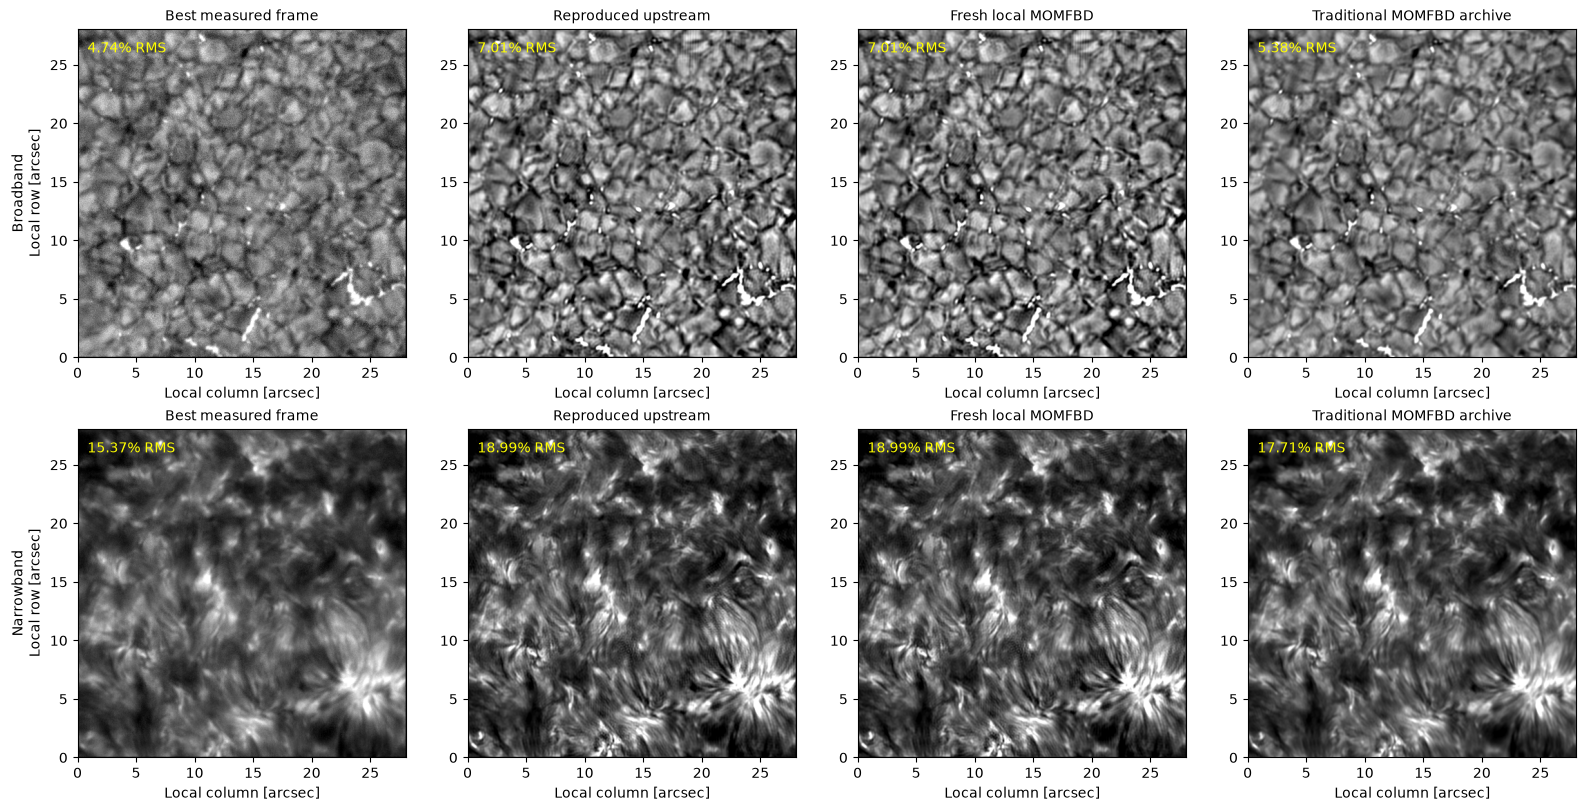

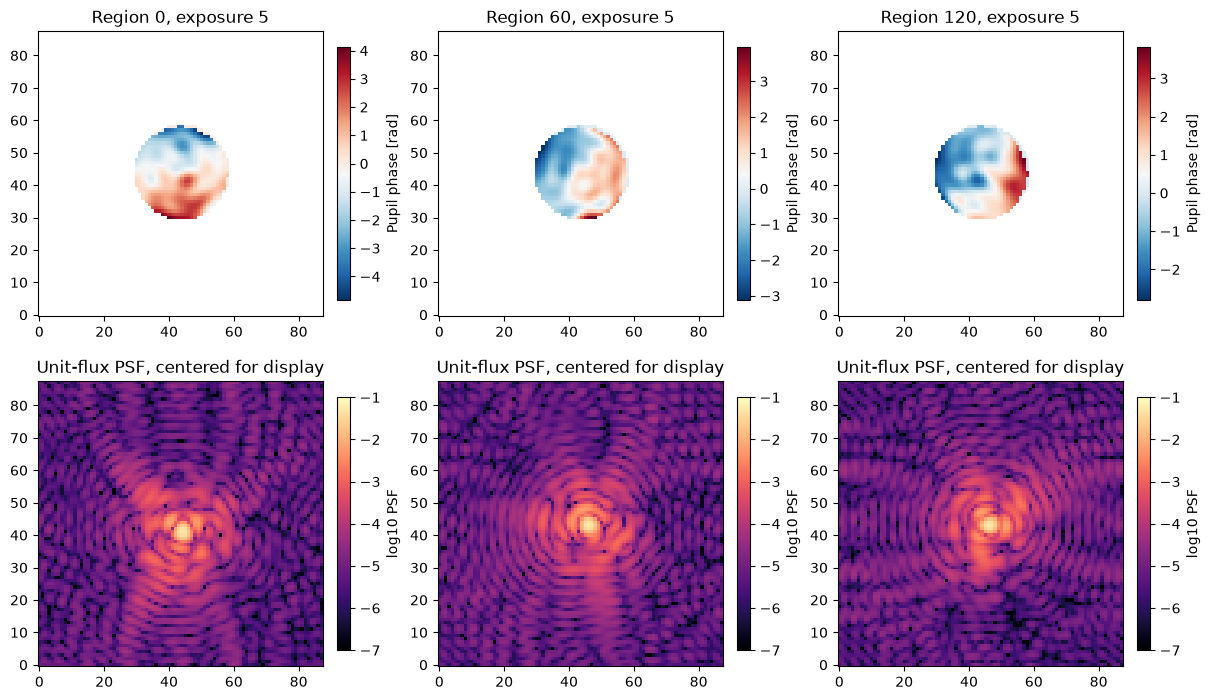

In [6]:
plot_comparison(best,upstream,fresh['reconstruction'][0],traditional)
plt.show()
plot_wavefront(fresh['wavefront_coefficients'][0],optics['pupil'].numpy(),optics['basis'].numpy())
plt.show()

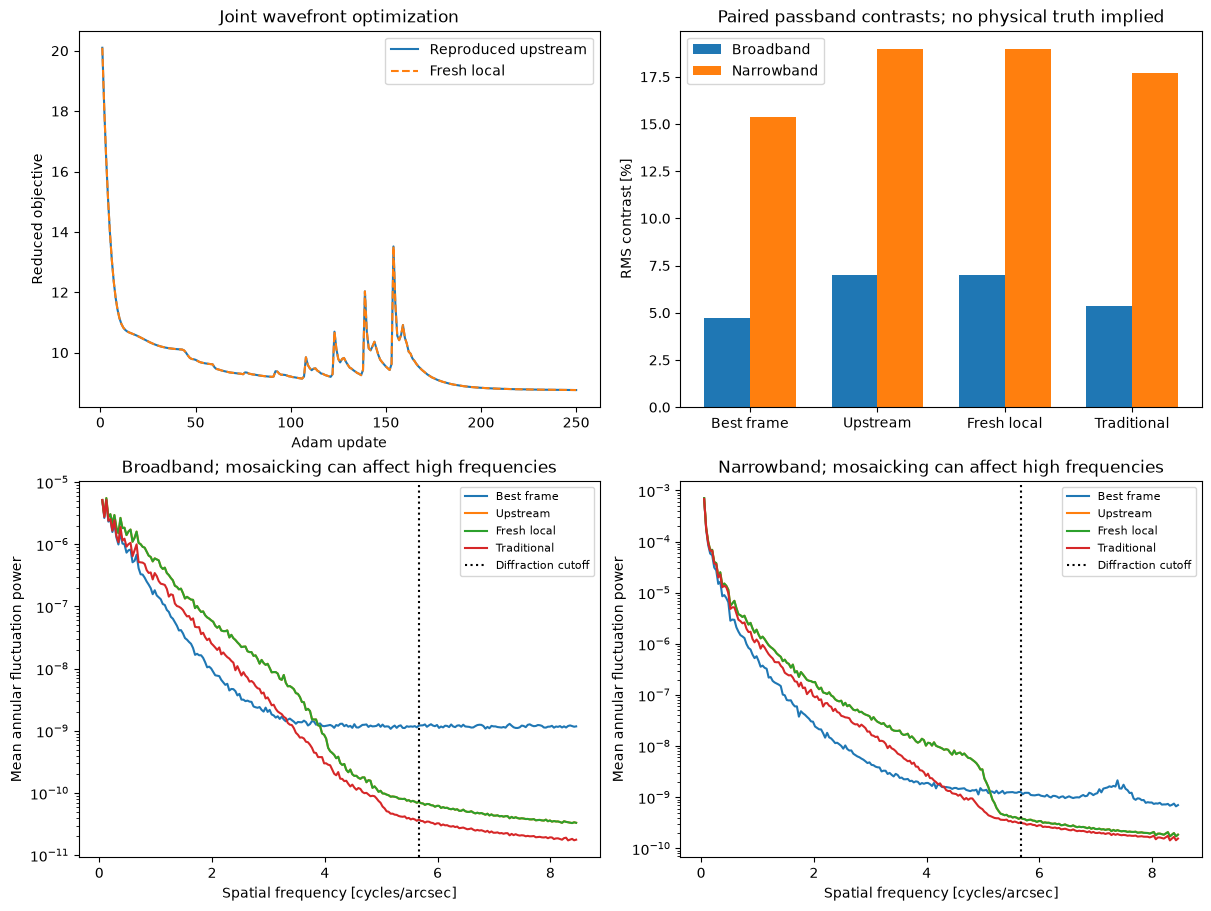

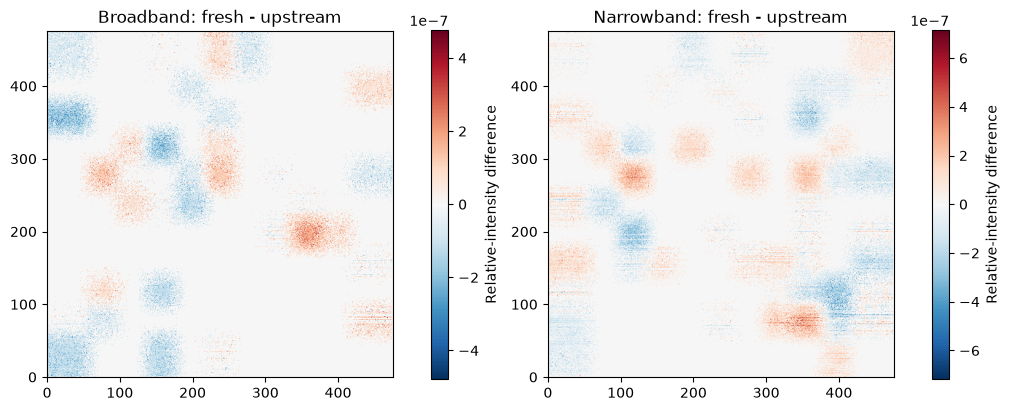

In [7]:
plot_diagnostics(fresh['loss_history'],upstream_loss,best,upstream,fresh['reconstruction'][0],traditional)
plt.show()
plot_differences(upstream,fresh['reconstruction'][0])
plt.show()

## 6. Conclusion

The reconstruction above jointly estimates atmospheric phase and two solar intensity fields across all 121 isoplanatic regions, twelve exposure pairs and the full supplied detector burst. Its independently computed Judge report establishes whether the fresh local method satisfies the fixed intensity, wavefront-derived PSF, observation-consistency and output-contract criteria. Stage parity, analytic operator tests and finite-difference derivatives provide separate evidence; passing the Judge alone does not replace them.

The independent traditional processing, reproduced original implementation and fresh reconstruction remain separately labeled. Increased RMS contrast or additional high-frequency power is not automatically physical improvement. Only twelve exposures, finite phase bandwidth, image-dependent noise estimation, patchwise shift invariance, passband approximations and mosaic seams limit the interpretation. Intensity-only phases are not unique, the translation and null-slot gauges are conventional, and no physical sharp-image truth is available. No claim is made that every recovered coefficient is independently measured or that this notebook reproduces the paper's other instruments and alternative NMF experiments.

The implemented equations, numerical exceptions and exact run provenance are detailed in `plan/approach.md`, `plan/design.md`, and `test/validation.md`. The public README plus measured NPZ and numerical environment define the independently solvable benchmark; this maintainer notebook and its reference assets are hidden from evaluated solvers.
